In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
df = pd.read_csv("netflix_customer_churn.csv")

In [ ]:
print(df.shape)

(5000, 14)


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   object 
 3   subscription_type       5000 non-null   object 
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   object 
 7   device                  5000 non-null   object 
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   object 
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   object 
dtypes: float64(3), int64(4), object(7)
memor

In [ ]:
print(df.head())

                            customer_id  age  gender subscription_type  \
0  a9b75100-82a8-427a-a208-72f24052884a   51   Other             Basic   
1  49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b   47   Other          Standard   
2  4d71f6ce-fca9-4ff7-8afa-197ac24de14b   27  Female          Standard   
3  d3c72c38-631b-4f9e-8a0e-de103cad1a7d   53   Other           Premium   
4  4e265c34-103a-4dbb-9553-76c9aa47e946   56   Other          Standard   

   watch_hours  last_login_days   region  device  monthly_fee  churned  \
0        14.73               29   Africa      TV         8.99        1   
1         0.70               19   Europe  Mobile        13.99        1   
2        16.32               10     Asia      TV        13.99        0   
3         4.51               12  Oceania      TV        17.99        1   
4         1.89               13   Africa  Mobile        13.99        1   

  payment_method  number_of_profiles  avg_watch_time_per_day favorite_genre  
0      Gift Card                

In [ ]:
print(df.describe())

print(df.describe(include="object"))

               age  watch_hours  last_login_days  monthly_fee      churned  \
count  5000.000000  5000.000000      5000.000000  5000.000000  5000.000000   
mean     43.847400    11.649450        30.089800    13.683400     0.503000   
std      15.501128    12.014654        17.536078     3.692062     0.500041   
min      18.000000     0.010000         0.000000     8.990000     0.000000   
25%      30.000000     3.337500        15.000000     8.990000     0.000000   
50%      44.000000     8.000000        30.000000    13.990000     1.000000   
75%      58.000000    16.030000        45.000000    17.990000     1.000000   
max      70.000000   110.400000        60.000000    17.990000     1.000000   

       number_of_profiles  avg_watch_time_per_day  
count         5000.000000             5000.000000  
mean             3.024400                0.874800  
std              1.415841                2.619824  
min              1.000000                0.000000  
25%              2.000000            

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64


In [ ]:
missing = df.isnull().sum()

print("Missing values per column:")
print(missing)
print(f"\nTotal missing values: {missing.sum()}")

if missing.sum() == 0:
    print("\n✅ No missing values in the dataset.")
else:
    missing[missing > 0].sort_values().plot(
        kind="bar",
        title="Missing Values by Column"
    )
    plt.ylabel("Number of missing values")
    plt.show()

Missing values per column:
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

Total missing values: 0

✅ No missing values in the dataset.


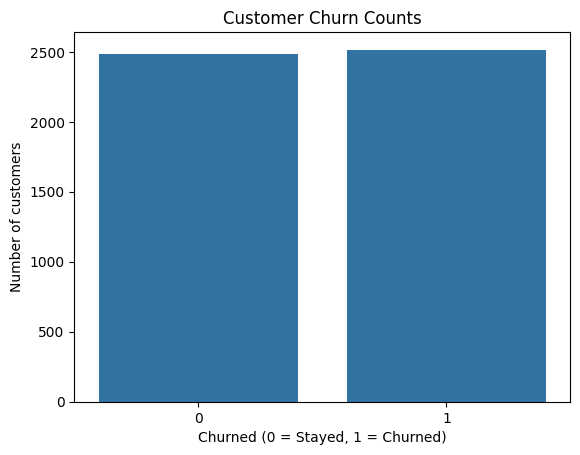

In [ ]:
sns.countplot(data=df, x="churned")

plt.title("Customer Churn Counts")
plt.xlabel("Churned (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of customers")
plt.show()

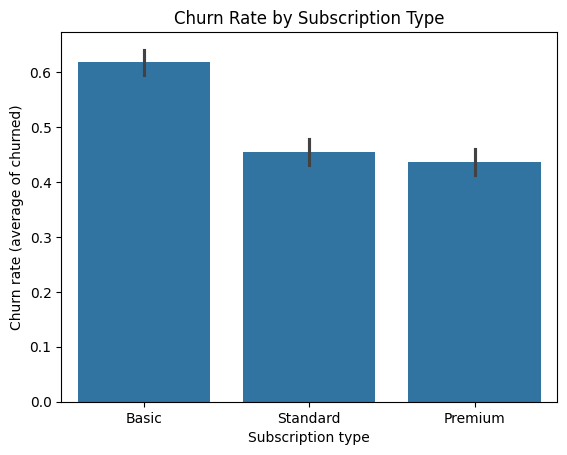

In [ ]:
sns.barplot(
    data=df,
    x="subscription_type",
    y="churned",
    order=["Basic", "Standard", "Premium"]
)

plt.title("Churn Rate by Subscription Type")
plt.xlabel("Subscription type")
plt.ylabel("Churn rate (average of churned)")
plt.show()

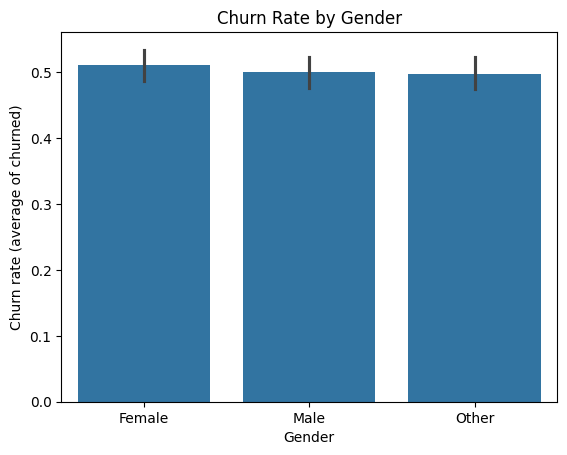

In [ ]:
sns.barplot(
    data=df,
    x="gender",
    y="churned",
    order=["Female", "Male", "Other"]
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn rate (average of churned)")
plt.show()

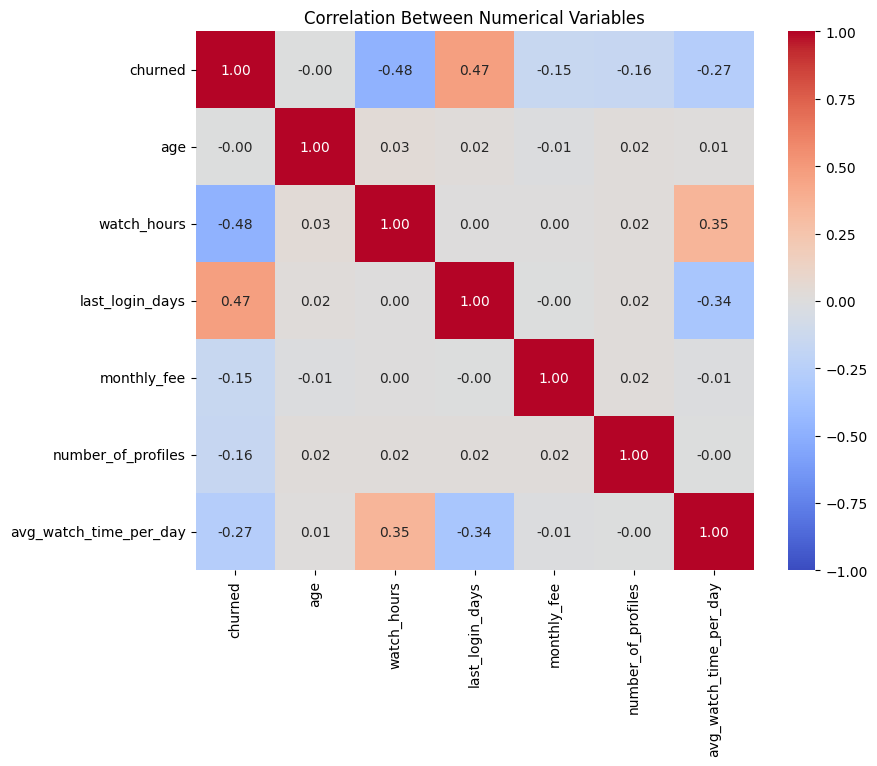

In [ ]:
num_cols = [
    "churned", "age", "watch_hours", "last_login_days",
    "monthly_fee", "number_of_profiles", "avg_watch_time_per_day"
]

plt.figure(figsize=(9, 7))
sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    center=0
)

plt.title("Correlation Between Numerical Variables")
plt.show()

In [ ]:
df = df.drop_duplicates()

print("Dataset shape:", df.shape)

Dataset shape: (5000, 14)


In [ ]:
df = df.drop(columns=["customer_id"])

KeyError: "['customer_id'] not found in axis"

In [ ]:
df["SingleProfile"] = (df["number_of_profiles"] == 1).astype(int)

print(
    df[["number_of_profiles", "SingleProfile"]].head()
)

   number_of_profiles  SingleProfile
0                   1              1
1                   5              0
2                   2              0
3                   2              0
4                   2              0


In [ ]:
# Engineered features (skip any you didn't create earlier)
df["ManyProfiles"] = (df["number_of_profiles"] >= 4).astype(int)
df["WatchHoursPerProfile"] = df["watch_hours"] / df["number_of_profiles"]
df["Inactive30"] = (df["last_login_days"] > 30).astype(int)

X = df[
    ["age", "gender", "subscription_type", "watch_hours",
     "last_login_days", "region", "device", "payment_method",
     "number_of_profiles", "avg_watch_time_per_day", "favorite_genre",
     "ManyProfiles", "WatchHoursPerProfile", "Inactive30"]
]

y = df["churned"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("\nShapes:", X.shape, y.shape)

Features:
   age  gender subscription_type  watch_hours  last_login_days   region  \
0   51   Other             Basic        14.73               29   Africa   
1   47   Other          Standard         0.70               19   Europe   
2   27  Female          Standard        16.32               10     Asia   
3   53   Other           Premium         4.51               12  Oceania   
4   56   Other          Standard         1.89               13   Africa   

   device payment_method  number_of_profiles  avg_watch_time_per_day  \
0      TV      Gift Card                   1                    0.49   
1  Mobile      Gift Card                   5                    0.03   
2      TV         Crypto                   2                    1.48   
3      TV         Crypto                   2                    0.35   
4  Mobile         Crypto                   2                    0.13   

  favorite_genre  ManyProfiles  WatchHoursPerProfile  Inactive30  
0         Action             0         

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("Training class proportions:")
print(y_train.value_counts(normalize=True))

print("Testing class proportions:")
print(y_test.value_counts(normalize=True))

Training rows: 4000
Testing rows: 1000
Training class proportions:
churned
1    0.503
0    0.497
Name: proportion, dtype: float64
Testing class proportions:
churned
1    0.503
0    0.497
Name: proportion, dtype: float64


In [ ]:
numeric_features = [
    "age", "watch_hours", "last_login_days", "number_of_profiles",
    "avg_watch_time_per_day", "WatchHoursPerProfile",
    "ManyProfiles", "Inactive30"
]

categorical_features = [
    "gender", "subscription_type", "region",
    "device", "payment_method", "favorite_genre"
]

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [ ]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore",
                              sparse_output=False))
])

In [ ]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [ ]:
X_train_prepared = preprocessor.fit_transform(X_train)

X_test_prepared = preprocessor.transform(X_test)

print("Training shape:", X_train_prepared.shape)
print("Testing shape:", X_test_prepared.shape)

Training shape: (4000, 37)
Testing shape: (1000, 37)


In [ ]:
print("Missing values in training:",
      np.isnan(X_train_prepared).sum())

print("Missing values in testing:",
      np.isnan(X_test_prepared).sum())

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Missing values in training: 0
Missing values in testing: 0
Training target shape: (4000,)
Testing target shape: (1000,)
